# Laboratory: Logical Reasoning for Planning
## Using an LLM to Construct and Test a Simple Planning Agent
 
**Central Idea:**  
$$\mathbf{Logic + Search = Planning}$$

### Learning Objectives
1. Describe a planning problem using states, actions, preconditions, and effects.
2. Determine whether an action is logically applicable in a given state ($S \models \text{Preconditions}(a)$).
3. Explain how logical reasoning and search work together in planning.
4. Use an LLM to generate a simple planning program.
5. Test and validate LLM-generated code.
6. Identify limitations of relying on an LLM to generate an intelligent agent.

---
# 2. Background & 3. Motivating Scenario

A planning problem is defined as $(I, A, G)$:
- $I$: Initial state
- $A$: Set of available actions (with preconditions and effects)
- $G$: Goal specification

An action $a$ is applicable in state $S$ if and only if $S \models \text{Preconditions}(a)$.  
When applied, $S' = (S \setminus \text{NegativeEffects}(a)) \cup \text{PositiveEffects}(a)$.

### Warehouse Scenario
- **Locations:** $A, B, C$ connected linearly ($A \leftrightarrow B \leftrightarrow C$).
- **Robot:** Starts at $A$.
- **Package:** Starts at $A$.
- **Goal:** Deliver package to $C$.

$$\mathbf{I} = \{At(\text{Robot}, A), \; At(\text{Package}, A)\}$$
$$\mathbf{G} = \{At(\text{Package}, C)\}$$

Initial State I: ['At(Package, A)', 'At(Robot, A)']
Goal G:          ['At(Package, C)']

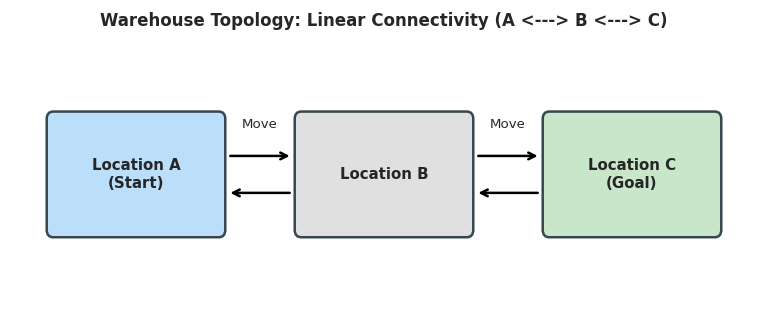

In [1]:
# Warehouse Problem Specification
I = {"At(Robot, A)", "At(Package, A)"}
G = {"At(Package, C)"}
print(f"Initial State I: {sorted(list(I))}")
print(f"Goal G:          {sorted(list(G))}")

---
# Task 0: Understand the Planning Problem

### (a) Initial State $I$
$$I = \{At(\text{Robot}, A), \; At(\text{Package}, A)\}$$

### (b) Goal $G$
$$G = \{At(\text{Package}, C)\}$$

### (c) Available Actions
- $\text{Move}(u, v)$ for $(u, v) \in \{(A, B), (B, A), (B, C), (C, B)\}$
- $\text{PickUp}(\text{Package}, l)$ for $l \in \{A, B, C\}$
- $\text{Drop}(\text{Package}, l)$ for $l \in \{A, B, C\}$

### (d) Action Preconditions and Effects

| Action | Positive Preconditions | Negative Preconditions | Positive Effects | Negative Effects |
| :--- | :--- | :--- | :--- | :--- |
| $\text{Move}(u, v)$ | $At(\text{Robot}, u)$ | — | $At(\text{Robot}, v)$ | $At(\text{Robot}, u)$ |
| $\text{PickUp}(\text{Package}, l)$ | $At(\text{Robot}, l), \; At(\text{Package}, l)$ | $\text{Holding}(\text{Package})$ | $\text{Holding}(\text{Package})$ | $At(\text{Package}, l)$ |
| $\text{Drop}(\text{Package}, l)$ | $At(\text{Robot}, l), \; \text{Holding}(\text{Package})$ | — | $At(\text{Package}, l)$ | $\text{Holding}(\text{Package})$ |

---

### Questions
- **Is $\text{PickUp}(\text{Package}, A)$ applicable from $I$?**  
  **Yes.** Both preconditions $At(\text{Robot}, A)$ and $At(\text{Package}, A)$ are present in $I$.
- **Is $\text{Drop}(\text{Package}, C)$ applicable from $I$?**  
  **No.** Preconditions are $At(\text{Robot}, C)$ and $\text{Holding}(\text{Package})$. Neither is present in $I$.

### Think About It (Task 0)
An action is not applicable merely because it exists in the action list. It is applicable only when its preconditions are logically entailed by the current state ($S \models \text{Pre}(a)$).

---
# Task 1: Construct a Plan by Hand

### Plan Sequence:
1. $a_1 = \text{PickUp}(\text{Package}, A)$
2. $a_2 = \text{Move}(A, B)$
3. $a_3 = \text{Move}(B, C)$
4. $a_4 = \text{Drop}(\text{Package}, C)$

### State Trace:

| State | Action | Facts Present | Preconditions Satisfied? |
| :---: | :--- | :--- | :---: |
| **$S_0$** | *(Initial)* | $At(\text{Robot}, A), \; At(\text{Package}, A)$ | — |
| **$S_1$** | $\text{PickUp}(\text{Package}, A)$ | $At(\text{Robot}, A), \; \text{Holding}(\text{Package})$ | Yes |
| **$S_2$** | $\text{Move}(A, B)$ | $At(\text{Robot}, B), \; \text{Holding}(\text{Package})$ | Yes |
| **$S_3$** | $\text{Move}(B, C)$ | $At(\text{Robot}, C), \; \text{Holding}(\text{Package})$ | Yes |
| **$S_4$** | $\text{Drop}(\text{Package}, C)$ | $At(\text{Robot}, C), \; At(\text{Package}, C)$ | Yes ($S_4 \models G$) |

In [2]:
# Task 1 Verification
s0 = {'At(Robot, A)', 'At(Package, A)'}
s1 = (s0 - {'At(Package, A)'}) | {'Holding(Package)'}
s2 = (s1 - {'At(Robot, A)'}) | {'At(Robot, B)'}
s3 = (s2 - {'At(Robot, B)'}) | {'At(Robot, C)'}
s4 = (s3 - {'Holding(Package)'}) | {'At(Package, C)'}

print("S0:", sorted(list(s0)))
print("S1:", sorted(list(s1)))
print("S2:", sorted(list(s2)))
print("S3:", sorted(list(s3)))
print("S4:", sorted(list(s4)))
print("Goal Achieved:", {'At(Package, C)'}.issubset(s4))

S0: ['At(Package, A)', 'At(Robot, A)']
S1: ['At(Robot, A)', 'Holding(Package)']
S2: ['At(Robot, B)', 'Holding(Package)']
S3: ['At(Robot, C)', 'Holding(Package)']
S4: ['At(Package, C)', 'At(Robot, C)']
Goal Achieved: True

---
# Task 2: Ask an LLM to Implement the Planner

### Specification Prompt:
```text
I want to implement a simple planning agent in Python.
Represent a state as a set of logical propositions.
Each action should contain:
• a name;
• positive preconditions;
• negative preconditions;
• positive effects;
• negative effects.
An action is applicable if all of its preconditions are satisfied by the current state.
When an action is applied:
1. remove its negative effects from the state;
2. add its positive effects to the state.
Use breadth-first search to find a sequence of actions that achieves a specified goal.
The program should also:
• detect when no plan exists;
• print the resulting sequence of actions;
• print the states reached after each action.
Explain the implementation and identify any assumptions you make.
Run the generated program on the warehouse problem.
```

### Think About It (Task 2 Mapping)
- **Preconditions:** Guard condition (`pos_pre <= state` and `neg_pre.isdisjoint(state)`).
- **Effects:** State transition update (`(state - neg_eff) | pos_eff`).
- **Goal:** Termination check (`goal <= state`).
- **BFS:** Queue exploration guarantees the shortest action sequence.

In [3]:
from collections import deque
from typing import List, Set, FrozenSet, Tuple, Optional

class Action:
    def __init__(self, name: str, pos_pre=None, neg_pre=None, pos_eff=None, neg_eff=None):
        self.name = name
        self.pos_pre: FrozenSet[str] = frozenset(pos_pre or [])
        self.neg_pre: FrozenSet[str] = frozenset(neg_pre or [])
        self.pos_eff: FrozenSet[str] = frozenset(pos_eff or [])
        self.neg_eff: FrozenSet[str] = frozenset(neg_eff or [])

    def is_applicable(self, state: FrozenSet[str]) -> bool:
        return self.pos_pre.issubset(state) and self.neg_pre.isdisjoint(state)

    def apply(self, state: FrozenSet[str]) -> FrozenSet[str]:
        return (state - self.neg_eff) | self.pos_eff


class PlanningProblem:
    def __init__(self, initial_state: Set[str], goal: Set[str], actions: List[Action]):
        self.initial_state: FrozenSet[str] = frozenset(initial_state)
        self.goal: FrozenSet[str] = frozenset(goal)
        self.actions: List[Action] = actions


def breadth_first_search_planner(problem: PlanningProblem) -> Tuple[Optional[List[str]], Optional[List[FrozenSet[str]]]]:
    if problem.goal.issubset(problem.initial_state):
        return [], [problem.initial_state]

    frontier = deque([(problem.initial_state, [], [problem.initial_state])])
    visited = {problem.initial_state}

    while frontier:
        state, plan, history = frontier.popleft()

        for action in problem.actions:
            if action.is_applicable(state):
                succ = action.apply(state)
                if succ not in visited:
                    visited.add(succ)
                    new_plan = plan + [action.name]
                    new_hist = history + [succ]

                    if problem.goal.issubset(succ):
                        return new_plan, new_hist

                    frontier.append((succ, new_plan, new_hist))

    return None, None


def print_plan(plan: Optional[List[str]], history: Optional[List[FrozenSet[str]]]):
    if plan is None:
        print("No plan found")
        return
    print(f"Plan found ({len(plan)} actions):")
    for i, (act, s) in enumerate(zip(plan, history[1:]), 1):
        print(f"  Step {i}: {act}")
        print(f"          State: {sorted(list(s))}")

---
# Task 3: Test the Generated Planner

We evaluate the planner across three test cases:
- **Test A (Solvable):** Original problem. Must find plan reaching $At(\text{Package}, C)$.
- **Test B (Impossible):** PickUp action removed. Must report "No plan found".
- **Test C (Irrelevant Actions):** Robot can move between locations but cannot pick up or drop package. Robot reaching $C$ must not be treated as package reaching $C$.

In [4]:
def create_actions(allow_pickup=True, allow_drop=True):
    locs = ['A', 'B', 'C']
    adj = [('A', 'B'), ('B', 'A'), ('B', 'C'), ('C', 'B')]
    acts = []
    
    # Move
    for u, v in adj:
        acts.append(Action(f"Move({u}, {v})", 
                           pos_pre=[f"At(Robot, {u})"], 
                           pos_eff=[f"At(Robot, {v})"], 
                           neg_eff=[f"At(Robot, {u})"]))
    # PickUp
    if allow_pickup:
        for l in locs:
            acts.append(Action(f"PickUp(Package, {l})",
                               pos_pre=[f"At(Robot, {l})", f"At(Package, {l})"],
                               neg_pre=["Holding(Package)"],
                               pos_eff=["Holding(Package)"],
                               neg_eff=[f"At(Package, {l})"]))
    # Drop
    if allow_drop:
        for l in locs:
            acts.append(Action(f"Drop(Package, {l})",
                               pos_pre=[f"At(Robot, {l})", "Holding(Package)"],
                               pos_eff=[f"At(Package, {l})"],
                               neg_eff=["Holding(Package)"]))
    return acts

# Test A
print("=== Test A: Solvable Problem ===")
p_a = PlanningProblem({'At(Robot, A)', 'At(Package, A)'}, {'At(Package, C)'}, create_actions(True, True))
plan_a, hist_a = breadth_first_search_planner(p_a)
print_plan(plan_a, hist_a)

# Test B
print("\n=== Test B: Impossible Problem (No PickUp) ===")
p_b = PlanningProblem({'At(Robot, A)', 'At(Package, A)'}, {'At(Package, C)'}, create_actions(False, True))
plan_b, hist_b = breadth_first_search_planner(p_b)
print_plan(plan_b, hist_b)

# Test C
print("\n=== Test C: Irrelevant Actions (Robot Move Only) ===")
p_c = PlanningProblem({'At(Robot, A)', 'At(Package, A)'}, {'At(Package, C)'}, create_actions(False, False))
plan_c, hist_c = breadth_first_search_planner(p_c)
print_plan(plan_c, hist_c)

=== Test A: Solvable Problem ===
Plan found (4 actions):
  Step 1: PickUp(Package, A)
          State: ['At(Robot, A)', 'Holding(Package)']
  Step 2: Move(A, B)
          State: ['At(Robot, B)', 'Holding(Package)']
  Step 3: Move(B, C)
          State: ['At(Robot, C)', 'Holding(Package)']
  Step 4: Drop(Package, C)
          State: ['At(Package, C)', 'At(Robot, C)']

=== Test B: Impossible Problem (No PickUp) ===
No plan found

=== Test C: Irrelevant Actions (Robot Move Only) ===
No plan found

### Test Results Summary

| Test | Initial State | Goal | Plan Found? | Resulting Plan | Plan Valid? |
| :--- | :--- | :--- | :---: | :--- | :---: |
| **Test A: Solvable** | $At(R, A), At(P, A)$ | $At(P, C)$ | **Yes** | $\langle PickUp(P, A), Move(A, B), Move(B, C), Drop(P, C) \rangle$ | Yes |
| **Test B: Impossible** | $At(R, A), At(P, A)$ | $At(P, C)$ | **No** | *No plan found* | Yes |
| **Test C: Irrelevant Actions** | $At(R, A), At(P, A)$ | $At(P, C)$ | **No** | *No plan found* | Yes |

---
# Task 4: Logic and Search

### Roles:
- **Logical component:** Determines applicability ($S \models \text{Pre}(a)$) and computes state transitions ($S' = \text{Apply}(S, a)$).
- **Search component:** Explores sequences of applicable actions to find a path to the goal.

### Completed Flow Description:
```text
         Current state
               ↓
    Check action preconditions
               ↓
   [ Determine applicable actions ]
               ↓
     Generate successor state
               ↓
    Search over alternatives
               ↓
             Goal?
```

### Explanation:
Logical reasoning defines legal transitions locally; search navigates through the resulting state space globally.
> **"Logic determines what is possible; search determines what to try."**

---
# Task 5: (Optional) Can the LLM Verify Its Own Plan?

### Question: Which should you trust more?
**(a) The LLM's explanation**  
**(b) The independently executed state transitions**

**Answer: (b) The independently executed state transitions.**

**Why:** An LLM generates text statistically and may produce plausible explanations that overlook missing preconditions or state inconsistencies. An independent execution program deterministically evaluates formal state updates.
> **"A generated explanation is not the same as an independent verification."**

### Reflection Questions

**1. Why is it useful to specify action preconditions and effects before asking an LLM to write the planner?**  
It provides precise semantics, preventing the LLM from making incorrect assumptions about domain physics or action behavior.

**2. Give an example of an error that could occur if the planner failed to check an action's preconditions.**  
The robot could drop an object without holding it, or pick up a package located at $A$ while the robot is at $C$.

**3. Why is a plan that "looks reasonable" not necessarily a valid plan?**  
A plan may appear intuitively sound in language while violating hidden physical constraints (e.g., disconnected locations or unheld items).

**4. What did the LLM contribute to the implementation?**  
It provided the code skeleton, data structure definitions, and standard BFS search loop.

**5. What did you have to verify independently?**  
State transition correctness (delete before add), state hashing (`frozenset`), termination on unsolvable problems, and plan validity.

**6. In this laboratory, where is logical reasoning being used?**  
In testing action applicability ($S \models \text{Pre}(a)$), updating state facts, and evaluating the goal condition ($S \models G$).

**7. How is planning related to the search algorithms studied in the previous module?**  
Planning uses the same search algorithms (e.g., BFS, A*), but the state transitions are generated dynamically via logical operators rather than from a pre-defined static graph.

---
# 6. Takeaway

$$\mathbf{Logical \; reasoning + Search \longrightarrow Planning}$$

- **Logic** determines whether actions are applicable and how they change the world.
- **Search** explores possible sequences of actions.
- **Workflow:** $\text{Understand} \longrightarrow \text{Specify} \longrightarrow \text{Generate} \longrightarrow \text{Execute} \longrightarrow \text{Verify}$.

---
# 7. Optional Extension: Prolog as a Logical Verifier

### 7.1 Prolog Basics
A Prolog program consists of:
- **Facts:** e.g., `penguin(polly).`
- **Rules:** e.g., `bird(X) :- penguin(X).`
- **Queries:** e.g., `?- animal(polly).`

---
# Task 6: Prolog as a Plan Verifier

Knowledge base (`planner.pl`):
```prolog
connected(a,b).
connected(b,a).
connected(b,c).
connected(c,b).

can_move(X,Y) :-
    connected(X,Y).
```

In [5]:
class MiniProlog:
    """Embedded lightweight Horn-clause query evaluator."""
    def __init__(self):
        self.facts = set()
        self.rules = []

    def add_fact(self, pred, *args):
        self.facts.add((pred, tuple(args)))

    def add_rule(self, head_pred, head_args, body):
        self.rules.append(((head_pred, tuple(head_args)), body))

    def query(self, pred, *args):
        target = (pred, tuple(args))
        # Direct fact
        if target in self.facts:
            return True
        # Rule check
        for (r_pred, r_args), body in self.rules:
            if r_pred == pred and len(r_args) == len(args):
                env = {ra: a for ra, a in zip(r_args, args) if ra.isupper()}
                all_sat = True
                for b_pred, b_args in body:
                    sub_args = tuple(env.get(ba, ba) for ba in b_args)
                    if (b_pred, sub_args) not in self.facts:
                        all_sat = False
                        break
                if all_sat:
                    return True
        return False

# Task 6 Knowledge Base
kb = MiniProlog()
kb.add_fact("connected", "a", "b")
kb.add_fact("connected", "b", "a")
kb.add_fact("connected", "b", "c")
kb.add_fact("connected", "c", "b")
kb.add_rule("can_move", ("X", "Y"), [("connected", ("X", "Y"))])
kb.add_rule("valid_move", ("X", "Y"), [("connected", ("X", "Y"))])

print("?- can_move(a, b). ->", kb.query("can_move", "a", "b"))
print("?- can_move(a, c). ->", kb.query("can_move", "a", "c"))

?- can_move(a, b). -> True
?- can_move(a, c). -> False

### Task 6 Questions
**(a) Why does Prolog return `true` for `can_move(a,b)`?**  
The rule reduces `can_move(a,b)` to `connected(a,b)`, which exists as an asserted fact.

**(b) Why does it not establish `can_move(a,c)`?**  
`connected(a,c)` does not exist in the knowledge base; under negation-as-failure, unprovable queries evaluate to `false`.

**(c) What is the relationship between the Prolog rule and logical implication?**  
`can_move(X,Y) :- connected(X,Y)` corresponds to $\text{Connected}(X, Y) \to \text{CanMove}(X, Y)$ (equivalent to clause $\neg \text{Connected}(X, Y) \lor \text{CanMove}(X, Y)$).

---
# Task 7: Using Prolog to Check a Proposed Plan

In [6]:
# Task 7 Checks
print("Checking plan: Move(a, b), Move(b, c)")
print("?- valid_move(a, b). ->", kb.query("valid_move", "a", "b"))
print("?- valid_move(b, c). ->", kb.query("valid_move", "b", "c"))
print("?- valid_move(a, c). ->", kb.query("valid_move", "a", "c"))

# Challenge
print("\nChallenge: Move(a, c) proposed by Python planner:")
if not kb.query("valid_move", "a", "c"):
    print("Action Move(a, c) rejected by Prolog verifier (no direct connection).")

Checking plan: Move(a, b), Move(b, c)
?- valid_move(a, b). -> True
?- valid_move(b, c). -> True
?- valid_move(a, c). -> False

Challenge: Move(a, c) proposed by Python planner:
Action Move(a, c) rejected by Prolog verifier (no direct connection).

---
# Task 8: Connect Prolog to Logical Reasoning

Program:
```prolog
wet_road.
slippery :-
    wet_road.
reduce_speed :-
    slippery.
```
Query: `?- reduce_speed.`

In [7]:
kb2 = MiniProlog()
kb2.add_fact("wet_road")
kb2.add_rule("slippery", (), [("wet_road", ())])
kb2.add_rule("reduce_speed", (), [("slippery", ())])

print("?- reduce_speed. ->", kb2.query("reduce_speed"))

?- reduce_speed. -> True

### Explanation:
The query succeeds via forward/backward application of Modus Ponens:
$$\mathbf{Fact \implies Rule \implies Rule \implies Conclusion}$$
$$\mathbf{wet\_road} \implies (\mathbf{wet\_road} \to \mathbf{slippery}) \implies (\mathbf{slippery} \to \mathbf{reduce\_speed}) \implies \mathbf{reduce\_speed}$$

---
# 7.2 Reflection (Prolog Extension)

**1. Difference between a Prolog fact and a Prolog rule:**  
A fact is an unconditional assertion; a rule is a conditional implication that holds only if its body conditions are satisfied.

**2. How a Prolog query corresponds to asking whether something follows from a knowledge base:**  
A query asks whether the goal formula is logically entailed by the knowledge base ($KB \models Q$).

**3. Why might it be useful to use a Prolog program to verify a plan generated by a Python program?**  
It provides a declarative, independent verification layer separate from procedural search algorithms.

**4. What advantage does an independent verifier provide when the original plan was generated with the help of an LLM?**  
It provides formal, deterministic verification, ensuring an AI-generated plan does not violate safety or physical constraints regardless of how plausible the plan looks.